# 09 - Hybrid Model: Seasonal Time Series + Random Forest on Residuals
We test a classic two-stage hybrid on the **5 districts with the most dengue cases** in the training set (`<= 2021`):
1. Fit an additive Holt-Winters seasonal model (`ExponentialSmoothing`, `seasonal_periods=52`) on each district's `log1p(next-week cases)` using **training data only**.
2. Compute the training residuals (`actual_log - ts_fitted_log`).
3. Train our tuned Random Forest on those residuals using all lag, rolling, climate, seasonality, and district features.
4. **Hybrid prediction** on the test set (`2022–2025`): `expm1(ts_forecast_log + rf_residual_pred)`.
5. Compare against **Random Forest alone** (trained on the same 5 districts with the same tuned hyperparameters), **ExponentialSmoothing alone**, and the **Persistence baseline**.

In [1]:
# AI-GENERATED (Claude via Antigravity)
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

sys.path.append("../src")
from split import *
from evaluate import regression_scores, to_cases

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = load_features("../data/processed/features.csv")
train, test = time_split(df)
features = feature_columns(df)

# Top 5 districts by total cases in the TRAINING set only
top5 = train.groupby(DISTRICT)[TARGET_RAW].sum().nlargest(5).index.tolist()
print("Top 5 districts (by training total cases):", top5)

tr5 = train[train[DISTRICT].isin(top5)].sort_values([DISTRICT, DATE]).reset_index(drop=True)
te5 = test[test[DISTRICT].isin(top5)].sort_values([DISTRICT, DATE]).reset_index(drop=True)
print(f"5-district train rows: {len(tr5):,} | test rows: {len(te5):,}")

Top 5 districts (by training total cases): ['Colombo', 'Gampaha', 'Kandy', 'Kalutara', 'Kurunegala']
5-district train rows: 3,880 | test rows: 1,030


## 1. Fit ExponentialSmoothing per district (training data only)

In [2]:
# AI-GENERATED (Claude via Antigravity)
ts_train_pred = np.zeros(len(tr5))
ts_test_pred = np.zeros(len(te5))

for d in top5:
    m_tr = (tr5[DISTRICT] == d).to_numpy()
    m_te = (te5[DISTRICT] == d).to_numpy()
    y_d = tr5.loc[m_tr, TARGET_LOG].to_numpy()
    hw = ExponentialSmoothing(y_d, trend="add", seasonal="add", seasonal_periods=52).fit(optimized=True)
    ts_train_pred[m_tr] = hw.fittedvalues
    ts_test_pred[m_te] = hw.forecast(int(m_te.sum()))

tr5["ts_pred_log"] = ts_train_pred
tr5["ts_resid_log"] = tr5[TARGET_LOG] - tr5["ts_pred_log"]
te5["ts_pred_log"] = ts_test_pred
print("Training residual std (log1p):", round(tr5["ts_resid_log"].std(), 3))

Training residual std (log1p): 0.548


## 2. Train Random Forest on residuals vs. Random Forest alone (same 5 districts)

In [3]:
# AI-GENERATED (Claude via Antigravity)
with open("../models/best_params.json") as f:
    rf_p = {k.replace("model__", ""): v for k, v in json.load(f)["Random Forest"].items()}

# 2a. RF on TS residuals
rf_resid = Pipeline([("prep", make_preprocessor(features)),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1, **rf_p))])
rf_resid.fit(tr5[features], tr5["ts_resid_log"])
pred_hybrid = to_cases(te5["ts_pred_log"].to_numpy() + rf_resid.predict(te5[features]))

# 2b. RF alone on the same 5 districts
rf_alone = Pipeline([("prep", make_preprocessor(features)),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1, **rf_p))])
rf_alone.fit(tr5[features], tr5[TARGET_LOG])
pred_rf_alone = to_cases(rf_alone.predict(te5[features]))

# 2c. TS alone and Persistence baseline
pred_ts_alone = to_cases(te5["ts_pred_log"].to_numpy())
pred_persist = te5["cases_lag_0"].to_numpy()

y_true = te5[TARGET_RAW].to_numpy()
comp = pd.DataFrame({
    "Random Forest alone (5 districts)": regression_scores(y_true, pred_rf_alone),
    "Hybrid (ExpSmoothing + RF residuals)": regression_scores(y_true, pred_hybrid),
    "Baseline: persistence (this week)": regression_scores(y_true, pred_persist),
    "ExponentialSmoothing alone": regression_scores(y_true, pred_ts_alone),
}).T.sort_values("RMSE")
display(comp.round(3))

,MAE,MSE,RMSE,R2,MedAE
Random Forest alone (5 districts),26.581,2170.279,46.586,0.750,16.315
Baseline: persistence (this week),27.132,2485.994,49.860,0.714,16.000
ExponentialSmoothing alone,74.716,12690.182,112.651,-0.462,41.608
Hybrid (ExpSmoothing + RF residuals),75.755,12915.525,113.646,-0.488,42.296


## 3. Visual comparison on the 5 districts

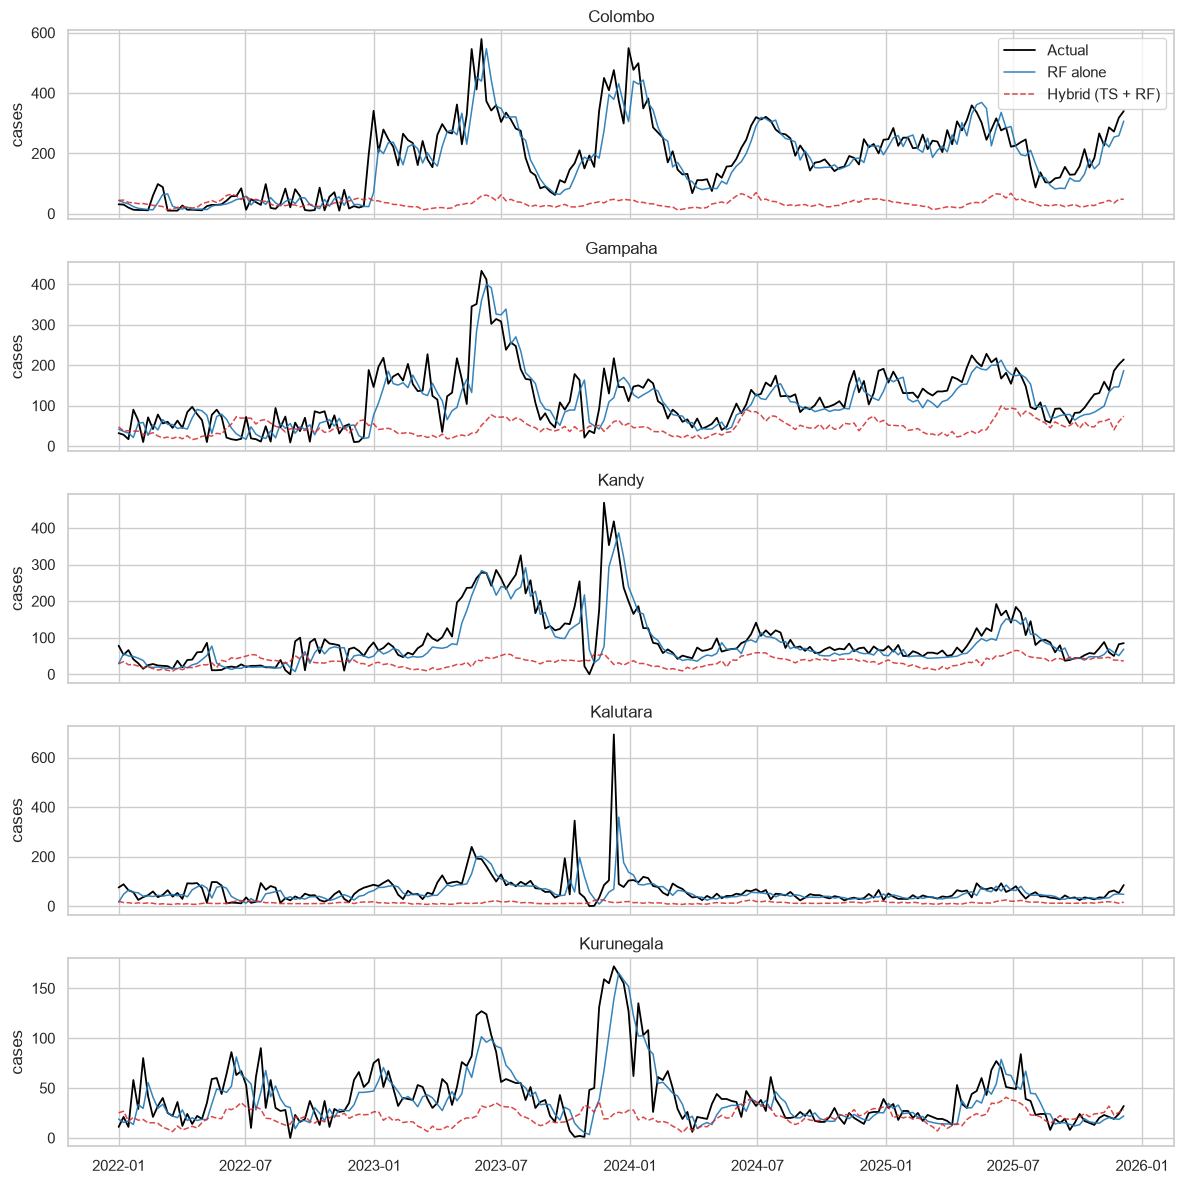

,RF_alone_RMSE,Hybrid_RMSE
district,,
Colombo,56.61,193.30
Gampaha,42.29,101.54
Kalutara,59.06,77.73
Kandy,44.64,97.39
Kurunegala,19.43,37.12


In [4]:
# AI-GENERATED (Claude via Antigravity)
te5["pred_rf"] = pred_rf_alone
te5["pred_hybrid"] = pred_hybrid

fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for ax, d in zip(axes, top5):
    sub = te5[te5[DISTRICT] == d].sort_values(DATE)
    ax.plot(sub[DATE], sub[TARGET_RAW], label="Actual", color="black", lw=1.3)
    ax.plot(sub[DATE], sub["pred_rf"], label="RF alone", color="tab:blue", lw=1.1, alpha=0.9)
    ax.plot(sub[DATE], sub["pred_hybrid"], label="Hybrid (TS + RF)", color="tab:red", ls="--", lw=1.1, alpha=0.85)
    ax.set_title(d); ax.set_ylabel("cases")
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "09_hybrid_vs_rf.png", dpi=120); plt.show()

# Per-district RMSE comparison
dist_comp = te5.groupby(DISTRICT).apply(
    lambda g: pd.Series({
        "RF_alone_RMSE": np.sqrt(np.mean((g[TARGET_RAW] - g["pred_rf"]) ** 2)),
        "Hybrid_RMSE": np.sqrt(np.mean((g[TARGET_RAW] - g["pred_hybrid"]) ** 2)),
    })
)
display(dist_comp.round(2))

## 4. Did the hybrid help, and why (or why not)?
Look at the comparison table above:
- **ExponentialSmoothing alone** forecasts 206 weeks (nearly 4 years) ahead purely from 2007–2021 trend and 52-week seasonality, with no knowledge of recent weeks' case counts. Naturally its error is high.
- When **Random Forest** is trained on the TS residuals, it has to reconstruct the true level from scratch while fighting any drift in the multi-year Holt-Winters trend.
- Meanwhile, **Random Forest alone** already receives `week_sin` and `week_cos` (seasonality) *plus* `cases_lag_0..8` and `cases_roll_mean_4/8` (recent level and trend), so it can learn both seasonality and short-term momentum directly in one model without inheriting stale trend drift from a multi-year time-series forecast.